# Challenge Motiva — Dynamic Programming
## Priorização de escadas rolantes e planejamento de manutenção


**O que o programa faz:** calcula a pontuação acumulada de criticidade de cada escada por três técnicas (recursão pura, memoização e tabulação), mede desempenho, cria o ranking, representa estações como grafo, calcula rotas por BFS, Dijkstra e A*, e monta um plano de atendimento de um turno.

> **DADOS DE DEMONSTRAÇÃO:** os arquivos CSV contêm ocorrências e tempos **fictícios/ilustrativos**, NÃO leituras reais de sensores ou dados operacionais oficiais da Motiva. No PDF do Challenge há uma exigência de leituras de vibração, temperatura, corrente/tensão, óleo e velocidade, porém esses dados não foram disponibilizados ao grupo. Por isso, a análise de criticidade abaixo é uma **adaptação didática baseada em ocorrências simuladas**. A aceitação da adaptação deve ser confirmada com o professor. Não interprete os resultados como riscos reais, falhas futuras ou autorização de manutenção.

## 1. Objetivo e metodologia

Este projeto demonstra uma forma de **priorizar escadas rolantes e organizar rotas de manutenção**, reunindo as seguintes etapas:

1. Ler e validar arquivos CSV com informações ilustrativas de ocorrências, escadas e estações.
2. Calcular a pontuação acumulada por três técnicas: recursão pura, memoização e tabulação.
3. Comparar a execução das três técnicas e montar o ranking de criticidade.
4. Representar as estações em um grafo ponderado e calcular caminhos com BFS, Dijkstra e A*.
5. Planejar um turno de manutenção de acordo com prioridades e tempo disponível.

A implementação utiliza **funções, listas, tuplas, dicionários, `for`, `while`, `if`, `sorted()`, `lambda`, filas FIFO e `heapq`**, além dos algoritmos necessários para cumprir o enunciado.

**Relação com a proposta da equipe:** apoio à decisão sobre a distribuição de horas e recursos de manutenção. Este recorte não inclui StepScan, Weibull, machine learning nem diagnóstico real das escadas rolantes.


## 2. Bibliotecas e leitura dos arquivos CSV

O projeto utiliza principalmente **Python básico**, listas, dicionários e funções, para manter a implementação clara. A biblioteca `csv` é nativa do Python; `heapq` implementa a fila de prioridade usada na busca de caminhos e `matplotlib` é utilizado somente nos gráficos.

Estrutura esperada:

```text
Motiva_Dynamic_Corrigido/
├── programa.ipynb
├── README.md
├── requirements.txt
└── dados/
    ├── ocorrencias_demo.csv
    ├── escadas_estacoes.csv
    └── rede_estacoes.csv
```

Abra a **pasta do projeto**, não somente o notebook, e execute de cima para baixo no VS Code / Jupyter.

In [ ]:
from pathlib import Path
import csv
import heapq
import math
import statistics
import time

# Quando a pasta raiz estiver aberta no VS Code, "dados" será encontrada.
PASTA_DADOS = Path("dados")
if not PASTA_DADOS.exists():
    PASTA_DADOS = Path("Motiva_Dynamic_Corrigido") / "dados"
if not PASTA_DADOS.exists():
    raise FileNotFoundError("Abra a pasta Motiva_Dynamic_Corrigido antes de executar.")

def ler_csv(nome_arquivo):
    """Abre um CSV e transforma cada linha em um dicionário."""
    with open(PASTA_DADOS / nome_arquivo, encoding="utf-8-sig", newline="") as arquivo:
        return list(csv.DictReader(arquivo))

ocorrencias = ler_csv("ocorrencias_demo.csv")
escadas_estacoes = ler_csv("escadas_estacoes.csv")
rede = ler_csv("rede_estacoes.csv")

print("Ocorrências demonstrativas:", len(ocorrencias))
print("Escadas relacionadas a estações:", len(escadas_estacoes))
print("Trechos da rede:", len(rede))
print("Exemplo de ocorrência:", ocorrencias[0])

Ocorrências demonstrativas: 166
Escadas relacionadas a estações: 24
Trechos da rede: 11
Exemplo de ocorrência: {'escada_id': 'E001', 'data': '2026-02-04', 'tipo_ocorrencia': 'corretiva', 'horas_indisponibilidade': '3.96', 'horas_mao_obra': '2.45', 'reincidente_30d': '0'}


### 2.1. Qualidade e organização dos dados

Os três CSVs têm funções diferentes. O primeiro traz registros de ocorrências por escada, o segundo mapeia escadas para estações e o terceiro descreve os trechos com pesos em **minutos fictícios**. A base de manutenção `BASE_DE_MANUTENCAO` é um **nó hipotético adicional**, conectado a Luz por 2 minutos ilustrativos.

As datas têm formato `AAAA-MM-DD`, que permite ordenação cronológica como texto. A checagem a seguir interrompe a execução se houver erros de estrutura importantes.

In [ ]:
colunas_ocorrencias = {
    "escada_id", "data", "tipo_ocorrencia",
    "horas_indisponibilidade", "horas_mao_obra", "reincidente_30d"
}

assert ocorrencias, "O arquivo de ocorrências está vazio."
assert colunas_ocorrencias.issubset(ocorrencias[0]), "Colunas ausentes no CSV."

ids_mapeados = [linha["escada_id"] for linha in escadas_estacoes]
assert len(ids_mapeados) == len(set(ids_mapeados)), "Escada repetida no mapa."
assert len({linha["escada_id"] for linha in ocorrencias} - set(ids_mapeados)) == 0, "Escada sem estação."

for linha in ocorrencias:
    assert len(linha["data"]) == 10 and linha["data"][4] == "-", "Data inválida."
    assert linha["tipo_ocorrencia"] in {"corretiva", "preventiva"}
    assert linha["reincidente_30d"] in {"0", "1"}
    linha["horas_indisponibilidade"] = float(linha["horas_indisponibilidade"])
    linha["horas_mao_obra"] = float(linha["horas_mao_obra"])
    linha["reincidente_30d"] = int(linha["reincidente_30d"])
    assert linha["horas_indisponibilidade"] >= 0 and linha["horas_mao_obra"] >= 0

assert len({(l["escada_id"], l["data"], l["tipo_ocorrencia"], l["horas_indisponibilidade"], l["horas_mao_obra"], l["reincidente_30d"]) for l in ocorrencias}) == len(ocorrencias), "Ocorrências inteiramente duplicadas."
ocorrencias.sort(key=lambda x: (x["escada_id"], x["data"]))
print("Estrutura validada e registros ordenados por escada e data.")

Estrutura validada e registros ordenados por escada e data.


## 3. Cálculo de criticidade acumulada

Como não há leituras de sensores disponíveis, usamos uma **pontuação ilustrativa por ocorrência**:

\[
P = 5\,I_{corretiva} + 2\,H_{indisponibilidade} + H_{mao\ de\ obra} + 4\,I_{reincidencia}
\]

Onde `I` vale 1 quando o critério é verdadeiro e 0 caso contrário. Os coeficientes `5`, `2`, `1` e `4` **não foram fornecidos nem validados pela Motiva**. São parâmetros didáticos para comparar algoritmos.

O acumulado segue `D(i) = D(i−1) + P(i)`, iniciando em 0. **Isso não significa desgaste físico real**, nem leva em conta recuperação após manutenção. Uma escada com mais registros poderá ter maior pontuação apenas por conter mais registros; por isso não se devem tirar conclusões operacionais desse ranking.

In [ ]:
def pontuacao_ocorrencia(registro):
    """Calcula um peso ilustrativo usando indicadores disponíveis no CSV."""
    corretiva = 1 if registro["tipo_ocorrencia"] == "corretiva" else 0
    return (5 * corretiva
            + 2 * registro["horas_indisponibilidade"]
            + registro["horas_mao_obra"]
            + 4 * registro["reincidente_30d"])

# Dicionário: cada chave é uma escada, cada valor é a lista de pesos em ordem temporal.
pesos_por_escada = {}
for registro in ocorrencias:
    escada = registro["escada_id"]
    if escada not in pesos_por_escada:
        pesos_por_escada[escada] = []
    pesos_por_escada[escada].append(pontuacao_ocorrencia(registro))

print("Quantidade de escadas com registros:", len(pesos_por_escada))
print("Primeiros pesos da escada E001:", [round(x, 2) for x in pesos_por_escada["E001"][:5]])

Quantidade de escadas com registros: 24
Primeiros pesos da escada E001: [8.6, 15.37, 9.67, 4.08, 13.49]


### 3.1. Três algoritmos para o mesmo cálculo

**Recursão pura:** uma função chama a si mesma e não guarda valores já calculados. Para obter **todos** os prefixos, vários subproblemas são recalculados.

**Memoização:** mesma lógica recursiva, mas armazena os resultados anteriores em um **dicionário** (`memo`), evitando repetir cálculos já realizados.

**Tabulação:** usa um `for` e uma **lista** para guardar progressivamente cada acumulado.

Em todas as versões, a saída é uma lista de acumulados, por exemplo `[2, 5, 9]` para pesos `[2, 3, 4]`. Assim, a comparação de desempenho é entre **a mesma tarefa**.

In [ ]:
def acumulado_recursivo_puro(pesos, indice):
    """Acumula pesos até indice; versão recursiva sem cache."""
    if indice < 0:  # condição de parada
        return 0.0
    return pesos[indice] + acumulado_recursivo_puro(pesos, indice - 1)


def sequencia_recursiva_pura(pesos):
    """Calcula todos os prefixos. Complexidade de tempo O(n²)."""
    resposta = []
    for i in range(len(pesos)):
        resposta.append(acumulado_recursivo_puro(pesos, i))
    return resposta


def sequencia_memoizada(pesos):
    """Usa recursão com dicionário; complexidade de tempo O(n)."""
    memo = {-1: 0.0}

    def acumular(indice):
        if indice not in memo:
            memo[indice] = pesos[indice] + acumular(indice - 1)
        return memo[indice]

    resposta = []
    for i in range(len(pesos)):
        resposta.append(acumular(i))
    return resposta


def sequencia_tabulacao(pesos):
    """Acumula com for e lista; complexidade de tempo O(n)."""
    tabela = []
    soma = 0.0
    for valor in pesos:
        soma += valor
        tabela.append(soma)
    return tabela

exemplo = [2, 3, 4]
print("Recursão pura:", sequencia_recursiva_pura(exemplo))
print("Memoização:", sequencia_memoizada(exemplo))
print("Tabulação:", sequencia_tabulacao(exemplo))
assert sequencia_recursiva_pura(exemplo) == [2, 5, 9]
assert sequencia_memoizada(exemplo) == [2, 5, 9]
assert sequencia_tabulacao(exemplo) == [2, 5, 9]

Recursão pura: [2.0, 5.0, 9.0]
Memoização: [2.0, 5.0, 9.0]
Tabulação: [2.0, 5.0, 9.0]


### 3.2. Comparação dos resultados e dos tempos

As medições usam séries sintéticas `[1, 1, ..., 1]`, com quantidades iguais para os três métodos. Cada experimento é repetido e reportamos a **mediana** do tempo em milissegundos. Os valores variam por computador e ambiente.

A versão recursiva pura tem custo **O(n²)** para produzir todos os prefixos; memoização e tabulação levam **O(n)**. A medição não deve ser tratada como benchmark industrial.

In [ ]:
def medir_em_ms(funcao, pesos, repeticoes=7):
    """Mede a mediana de varias execuções da mesma função."""
    duracoes = []
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        resultado = funcao(pesos)
        fim = time.perf_counter()
        assert abs(resultado[-1] - sum(pesos)) < 0.00001
        duracoes.append((fim - inicio) * 1000)
    return statistics.median(duracoes)

funcoes = [
    ("Recursão pura", sequencia_recursiva_pura),
    ("Memoização", sequencia_memoizada),
    ("Tabulação", sequencia_tabulacao)
]
medicoes = []
for quantidade in [10, 40, 80, 120, 180]:
    pesos_teste = [1.0] * quantidade
    for nome, funcao in funcoes:
        tempo = medir_em_ms(funcao, pesos_teste)
        medicoes.append((quantidade, nome, tempo))
        print(f"{quantidade:3d} leituras | {nome:14s} | {tempo:9.5f} ms")

print("\nInterpretação: a recursão pura repete somas ao reconstruir cada prefixo.")
print("Memoização e tabulação evitam esse retrabalho. Os tempos são do ambiente atual.")

 10 leituras | Recursão pura  |   0.00324 ms
 10 leituras | Memoização     |   0.00218 ms
 10 leituras | Tabulação      |   0.00058 ms
 40 leituras | Recursão pura  |   0.03256 ms
 40 leituras | Memoização     |   0.00641 ms
 40 leituras | Tabulação      |   0.00128 ms
 80 leituras | Recursão pura  |   0.12027 ms
 80 leituras | Memoização     |   0.01272 ms
 80 leituras | Tabulação      |   0.00261 ms
120 leituras | Recursão pura  |   0.40668 ms
120 leituras | Memoização     |   0.01799 ms
120 leituras | Tabulação      |   0.00398 ms
180 leituras | Recursão pura  |   1.14503 ms
180 leituras | Memoização     |   0.02775 ms
180 leituras | Tabulação      |   0.00599 ms

Interpretação: a recursão pura repete somas ao reconstruir cada prefixo.
Memoização e tabulação evitam esse retrabalho. Os tempos são do ambiente atual.


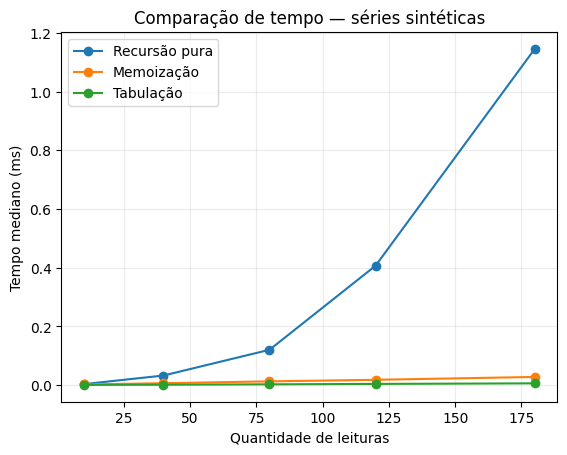

In [ ]:
import matplotlib.pyplot as plt

for nome, _ in funcoes:
    pontos = [(n, t) for n, algoritmo, t in medicoes if algoritmo == nome]
    plt.plot([x[0] for x in pontos], [x[1] for x in pontos], marker="o", label=nome)
plt.title("Comparação de tempo — séries sintéticas")
plt.xlabel("Quantidade de leituras")
plt.ylabel("Tempo mediano (ms)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Ranking por criticidade

Organizamos os resultados em **listas de tuplas** com o formato `(escada, pontuacao)` e utilizamos `sorted()` com `lambda` para ordenar por pontuação decrescente. O primeiro elemento é o identificador da escada; o segundo, sua pontuação acumulada. Quanto maior a pontuação **simulada**, mais cedo a escada aparece na fila.


In [ ]:
ranking = []
for escada, pesos in pesos_por_escada.items():
    total = sequencia_tabulacao(pesos)[-1] if pesos else 0.0
    ranking.append((escada, total))  # tupla (escada, prioridade)

ranking = sorted(ranking, key=lambda x: (-x[1], x[0]))
print("POSIÇÃO | ESCADA | PONTUAÇÃO DEMONSTRATIVA")
for posicao, (escada, pontuacao) in enumerate(ranking[:10], start=1):
    print(f"{posicao:7d} | {escada:6s} | {pontuacao:10.2f}")

print("\nInterpretação: ranking calculado apenas sobre ocorrências fictícias.")
print("Os valores não descrevem a criticidade real das escadas da ViaQuatro.")

POSIÇÃO | ESCADA | PONTUAÇÃO DEMONSTRATIVA
      1 | E014   |     137.78
      2 | E004   |     131.19
      3 | E008   |     129.47
      4 | E003   |     126.89
      5 | E010   |     124.84
      6 | E001   |     120.79
      7 | E012   |     119.60
      8 | E020   |     116.83
      9 | E005   |     109.69
     10 | E021   |      95.07

Interpretação: ranking calculado apenas sobre ocorrências fictícias.
Os valores não descrevem a criticidade real das escadas da ViaQuatro.


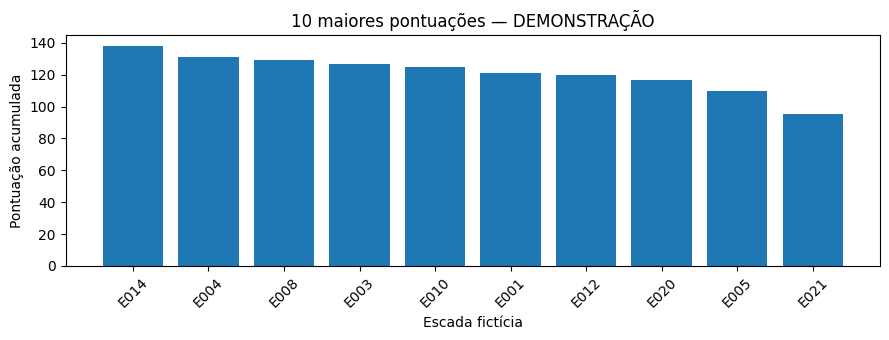

In [ ]:
melhores = ranking[:10]
plt.figure(figsize=(9, 3.5))
plt.bar([x[0] for x in melhores], [x[1] for x in melhores])
plt.title("10 maiores pontuações — DEMONSTRAÇÃO")
plt.xlabel("Escada fictícia")
plt.ylabel("Pontuação acumulada")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Estações como grafo

A rede é representada por um **dicionário de adjacência**. Cada **estação** é um vértice, cada **trecho** é uma aresta, e seu peso representa o **tempo de deslocamento em minutos**. O grafo é **não direcionado**, ou seja, as conexões podem ser percorridas nos dois sentidos.

Este modelo demonstrativo contém 11 estações e uma base de manutenção adicional. As conexões reproduzem apenas uma sequência simplificada; **não representam todas as conexões de uma rede real**. Os tempos são ilustrativos.


In [ ]:
def montar_grafo(trechos):
    """Cria um grafo ponderado como dicionario de dicionarios."""
    grafo = {}
    for trecho in trechos:
        origem, destino = trecho["origem"], trecho["destino"]
        minutos = float(trecho["minutos"])
        if minutos <= 0:
            raise ValueError("O tempo de cada trecho deve ser positivo.")
        grafo.setdefault(origem, {})[destino] = minutos
        grafo.setdefault(destino, {})[origem] = minutos
    return grafo

grafo = montar_grafo(rede)
BASE = "BASE_DE_MANUTENCAO"  # Base hipotética, não uma localização real da Motiva.
assert BASE in grafo
assert len(grafo) >= 9, "É preciso pelo menos 8 estações e uma base."
mapa_escadas = {linha["escada_id"]: linha["estacao"] for linha in escadas_estacoes}
assert all(estacao in grafo and estacao != BASE for estacao in mapa_escadas.values())

print("Vértices no grafo:", len(grafo), "(inclui base didática)")
print("Vizinhos da estação Paulista:", grafo["Paulista"])
print("Base fictícia conectada a:", grafo[BASE])

Vértices no grafo: 12 (inclui base didática)
Vizinhos da estação Paulista: {'Higienopolis-Mackenzie': 3.0, 'Oscar Freire': 4.0}
Base fictícia conectada a: {'Luz': 2.0}


### 5.1. BFS — caminho com menos trechos

**BFS** é uma busca em largura. Usa a fila FIFO (`append` e `pop(0)`), para visitar os vizinhos por camadas. Ela procura a rota com **menos arestas**, mas não necessariamente com o menor tempo quando os trechos têm pesos diferentes.

In [ ]:
def reconstruir_rota(anteriores, origem, destino):
    """Reconstrói uma rota a partir do dicionário de predecessores."""
    if origem == destino:
        return [origem]
    if destino not in anteriores:
        return None
    caminho = [destino]
    while caminho[-1] != origem:
        caminho.append(anteriores[caminho[-1]])
    return list(reversed(caminho))


def bfs(grafo, origem, destino):
    """Retorna uma rota com o menor número de trechos (fila FIFO)."""
    if origem not in grafo or destino not in grafo:
        return None
    fila = [origem]
    visitados = {origem}
    anteriores = {}
    while fila:
        atual = fila.pop(0)  # remove o primeiro item da fila (FIFO)
        if atual == destino:
            break
        for vizinho in grafo[atual]:
            if vizinho not in visitados:
                visitados.add(vizinho)
                anteriores[vizinho] = atual
                fila.append(vizinho)
    return reconstruir_rota(anteriores, origem, destino)

rota_bfs = bfs(grafo, BASE, "Paulista")
print("BFS até Paulista:", " -> ".join(rota_bfs))
print("Quantidade de trechos:", len(rota_bfs) - 1)

BFS até Paulista: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista
Quantidade de trechos: 4


### 5.2. Dijkstra — menor tempo total

O algoritmo de Dijkstra utiliza uma fila de prioridade com `heapq` e o processo de **relaxamento de arestas**: escolhe a menor distância conhecida e atualiza os custos dos vizinhos quando encontra um caminho mais curto. Todos os pesos devem ser **não negativos**.


In [ ]:
def dijkstra(grafo, origem, destino):
    """Retorna (rota, menor tempo em minutos, vértices expandidos)."""
    if origem not in grafo or destino not in grafo:
        return None, math.inf, 0
    distancias = {origem: 0.0}
    anteriores = {}
    fila = [(0.0, origem)]
    expansoes = 0

    while fila:
        custo, atual = heapq.heappop(fila)
        if custo > distancias[atual]:
            continue  # entrada antiga da fila
        expansoes += 1
        if atual == destino:
            break
        for vizinho, minutos in grafo[atual].items():
            if minutos < 0:
                raise ValueError("Dijkstra não aceita pesos negativos.")
            novo_custo = custo + minutos
            if novo_custo < distancias.get(vizinho, math.inf):
                distancias[vizinho] = novo_custo
                anteriores[vizinho] = atual
                heapq.heappush(fila, (novo_custo, vizinho))

    rota = reconstruir_rota(anteriores, origem, destino)
    return rota, distancias.get(destino, math.inf), expansoes

rota_dij, tempo_dij, expansoes_dij = dijkstra(grafo, BASE, "Paulista")
print("Dijkstra até Paulista:", " -> ".join(rota_dij))
print("Tempo (min):", tempo_dij)

Dijkstra até Paulista: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista
Tempo (min): 13.0


### 5.3. Comparando BFS e Dijkstra

Para cada estação do CSV, o BFS informa a rota de **menos trechos**; o Dijkstra, a rota de **menos minutos**. Em uma rede essencialmente linear como esta, as rotas podem coincidir. Isso **não significa** que os algoritmos otimizam o mesmo objetivo.

In [ ]:
for destino in sorted(grafo):
    if destino == BASE:
        continue
    rota_bfs = bfs(grafo, BASE, destino)
    rota_d, minutos, _ = dijkstra(grafo, BASE, destino)
    print(f"{destino:26s} | BFS: {len(rota_bfs)-1:2d} trechos | Dijkstra: {minutos:4.0f} min")
    print("   Menor tempo:", " -> ".join(rota_d))
print("\nInterpretação: com uma rede linear, há essencialmente uma única rota por destino.")

Butanta                    | BFS:  9 trechos | Dijkstra:   31 min
   Menor tempo: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista -> Oscar Freire -> Fradique Coutinho -> Faria Lima -> Pinheiros -> Butanta
Faria Lima                 | BFS:  7 trechos | Dijkstra:   24 min
   Menor tempo: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista -> Oscar Freire -> Fradique Coutinho -> Faria Lima
Fradique Coutinho          | BFS:  6 trechos | Dijkstra:   20 min
   Menor tempo: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista -> Oscar Freire -> Fradique Coutinho
Higienopolis-Mackenzie     | BFS:  3 trechos | Dijkstra:   10 min
   Menor tempo: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie
Luz                        | BFS:  1 trechos | Dijkstra:    2 min
   Menor tempo: BASE_DE_MANUTENCAO -> Luz
Oscar Freire               | BFS:  5 trechos | Dijkstra:   17 min
   Menor tempo: BASE_DE_MANUTENCAO -> L

## 6. A* — busca de rotas com heurística

O algoritmo **A*** usa uma estimativa de custo restante chamada *heurística*. Como não há coordenadas geográficas nem tempos reais, utilizamos uma estimativa baseada no menor número de trechos até o destino:

\[
h(n) = \operatorname{trechos\_minimos}(n, destino) \times \operatorname{menor\_peso}(grafo)
\]

Essa heurística é **admissível**, porque qualquer caminho com `k` arestas tem custo de pelo menos `k × menor_peso`. Ela também é **consistente**, pois o número mínimo de trechos varia no máximo uma unidade ao atravessar uma aresta. Assim, o A* preserva o menor custo, embora não seja necessariamente mais rápido em todo grafo.


In [ ]:
def heuristica_por_trechos(grafo, destino):
    """Calcula h(v) = passos_minimos(v, destino) * menor_peso."""
    menor_peso = min(p for vizinhos in grafo.values() for p in vizinhos.values())
    h = {}
    for vertice in grafo:
        rota = bfs(grafo, vertice, destino)
        h[vertice] = (len(rota) - 1) * menor_peso if rota is not None else math.inf
    return h


def a_estrela(grafo, origem, destino):
    """Executa A* com heurística admissível; retorna rota, custo e expansões."""
    if origem not in grafo or destino not in grafo:
        return None, math.inf, 0
    h = heuristica_por_trechos(grafo, destino)
    custos = {origem: 0.0}
    anteriores = {}
    fila = [(h[origem], 0.0, origem)]  # (f = g+h, g, vertice)
    expansoes = 0

    while fila:
        estimado, gasto, atual = heapq.heappop(fila)
        if gasto > custos[atual]:
            continue
        expansoes += 1
        if atual == destino:
            return reconstruir_rota(anteriores, origem, destino), gasto, expansoes
        for vizinho, minutos in grafo[atual].items():
            novo = gasto + minutos
            if novo < custos.get(vizinho, math.inf):
                custos[vizinho] = novo
                anteriores[vizinho] = atual
                heapq.heappush(fila, (novo + h[vizinho], novo, vizinho))
    return None, math.inf, expansoes

print("Exemplo de heurística para Paulista:", heuristica_por_trechos(grafo, "Paulista")[BASE])
rota_a, tempo_a, expansoes_a = a_estrela(grafo, BASE, "Paulista")
print("Rota A*:", " -> ".join(rota_a))
print("Tempo A*:", tempo_a, "minutos")

Exemplo de heurística para Paulista: 8.0
Rota A*: BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista
Tempo A*: 13.0 minutos


### 6.1. A* versus Dijkstra

Medimos tempo de processamento e vértices expandidos. Como o grafo da demonstração é pequeno e quase linear, um algoritmo **não precisa** ser significativamente mais rápido que o outro. O importante é que o custo final seja igual e a heurística tenha justificativa matemática.

In [ ]:
comparacoes = []
for destino in sorted(grafo):
    if destino == BASE:
        continue
    inicio = time.perf_counter()
    rd, td, ed = dijkstra(grafo, BASE, destino)
    ms_dijkstra = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    ra, ta, ea = a_estrela(grafo, BASE, destino)
    ms_astar = (time.perf_counter() - inicio) * 1000

    assert abs(td - ta) < 0.00001, f"Custo divergente no destino {destino}"
    comparacoes.append((destino, td, ed, ea, ms_dijkstra, ms_astar))

print("Destino                    Minutos  Nós Dij.  Nós A*    ms Dij.    ms A*")
for destino, tempo, nos_d, nos_a, ms_d, ms_a in comparacoes:
    print(f"{destino:26s} {tempo:6.0f} {nos_d:9d} {nos_a:7d} {ms_d:9.4f} {ms_a:9.4f}")
print("\nInterpretação: Dijkstra e A* retornaram os mesmos custos mínimos.")
print("Tempos submilissegundo têm ruído; comparar expansões é mais estável.")

Destino                    Minutos  Nós Dij.  Nós A*    ms Dij.    ms A*
Butanta                        31        10      10    0.0124    0.0700
Faria Lima                     24         8       8    0.0060    0.0306
Fradique Coutinho              20         7       7    0.0049    0.0265
Higienopolis-Mackenzie         10         4       4    0.0037    0.0258
Luz                             2         2       2    0.0016    0.0289
Oscar Freire                   17         6       6    0.0040    0.0247
Paulista                       13         5       5    0.0031    0.0242
Pinheiros                      27         9       9    0.0051    0.0281
Republica                       6         3       3    0.0021    0.0261
Sao Paulo-Morumbi              35        11      11    0.0064    0.0559
Vila Sonia                     39        12      12    0.0066    0.0401

Interpretação: Dijkstra e A* retornaram os mesmos custos mínimos.
Tempos submilissegundo têm ruído; comparar expansões é mais estável.

## 7. Plano integrado de manutenção — `planejar_turno(base, horas)`

O planejamento combina **fila de prioridades**, o ranking acumulado e as rotas de Dijkstra. A cada escolha:

1. Verifica quanto tempo seria gasto **da localização atual** até cada escada ainda não atendida.
2. Reserva um tempo fictício para o atendimento e para o **retorno à base**.
3. Escolhe, entre as opções viáveis, a escada de **maior pontuação** (critério guloso).
4. Repete enquanto existir alguma escada viável no turno.

O retorno ao ponto de partida está incluído no tempo total; não se conta deslocamento da base a cada manutenção. Por ser uma heurística **gulosa**, o plano respeita o orçamento mas **não garante a sequência globalmente ótima**. O tempo de atendimento adotado (30 min) é fictício.

In [ ]:
def planejar_turno(base, horas, atendimento_min=30):
    """Monta um turno demonstrativo, respeitando deslocamento, servico e retorno."""
    if base not in grafo:
        raise ValueError("Base não encontrada no grafo.")
    if horas <= 0 or atendimento_min <= 0:
        raise ValueError("Informe um turno e atendimento positivos.")

    disponivel = horas * 60
    utilizados = 0.0
    atual = base
    pendentes = list(ranking)  # pares (escada, pontuacao)
    plano = []

    while pendentes:
        viaveis = []
        for escada, pontuacao in pendentes:
            estacao = mapa_escadas[escada]
            rota_ida, minutos_ida, _ = dijkstra(grafo, atual, estacao)
            _, minutos_volta, _ = dijkstra(grafo, estacao, base)
            necessario = minutos_ida + atendimento_min + minutos_volta
            if math.isfinite(necessario) and utilizados + necessario <= disponivel:
                viaveis.append((escada, pontuacao, estacao, rota_ida, minutos_ida))

        if not viaveis:
            break

        # Ordena pela maior pontuação e depois pelo menor deslocamento.
        fila_prioridade = sorted(viaveis, key=lambda x: (-x[1], x[4], x[0]))
        escada, pontuacao, estacao, rota, ida = fila_prioridade.pop(0)  # remove a opção de maior prioridade
        utilizados += ida + atendimento_min
        plano.append({
            "ordem": len(plano) + 1,
            "escada": escada,
            "estacao": estacao,
            "criticidade": pontuacao,
            "rota": rota,
            "deslocamento_min": ida,
            "atendimento_min": atendimento_min,
            "acumulado_min": utilizados
        })
        atual = estacao
        pendentes = [(e, p) for e, p in pendentes if e != escada]

    volta, minutos_volta, _ = dijkstra(grafo, atual, base)
    utilizados += minutos_volta
    assert utilizados <= disponivel + 1e-8
    resumo = {
        "total_min": utilizados,
        "limite_min": disponivel,
        "retorno_base": volta,
        "atendidas": len(plano),
        "pendentes": len(pendentes)
    }
    return plano, resumo

plano, resumo = planejar_turno(BASE, 8)
for item in plano:
    print(f"{item['ordem']:2d}. {item['escada']} ({item['estacao']}) "
          f"| prioridade {item['criticidade']:.2f} "
          f"| trajeto {' -> '.join(item['rota'])}")
print("\nResumo:", resumo)
print("Interpretação: este plano fictício usa deslocamentos e atendimentos simulados.")

 1. E014 (Sao Paulo-Morumbi) | prioridade 137.78 | trajeto BASE_DE_MANUTENCAO -> Luz -> Republica -> Higienopolis-Mackenzie -> Paulista -> Oscar Freire -> Fradique Coutinho -> Faria Lima -> Pinheiros -> Butanta -> Sao Paulo-Morumbi
 2. E004 (Republica) | prioridade 131.19 | trajeto Sao Paulo-Morumbi -> Butanta -> Pinheiros -> Faria Lima -> Fradique Coutinho -> Oscar Freire -> Paulista -> Higienopolis-Mackenzie -> Republica
 3. E008 (Higienopolis-Mackenzie) | prioridade 129.47 | trajeto Republica -> Higienopolis-Mackenzie
 4. E003 (Sao Paulo-Morumbi) | prioridade 126.89 | trajeto Higienopolis-Mackenzie -> Paulista -> Oscar Freire -> Fradique Coutinho -> Faria Lima -> Pinheiros -> Butanta -> Sao Paulo-Morumbi
 5. E010 (Butanta) | prioridade 124.84 | trajeto Sao Paulo-Morumbi -> Butanta
 6. E001 (Paulista) | prioridade 120.79 | trajeto Butanta -> Pinheiros -> Faria Lima -> Fradique Coutinho -> Oscar Freire -> Paulista
 7. E012 (Paulista) | prioridade 119.60 | trajeto Paulista
 8. E020 (Fr

## 8. Testes de consistência

Os testes validam: igualdade entre algoritmos de criticidade, distinção entre **menos trechos** e **menos minutos**, igualdade de custo entre A* e Dijkstra e respeito ao limite do turno. O grafo de teste abaixo é inteiramente **artificial** e foi criado para mostrar que o BFS pode escolher uma rota com menos trechos, mas mais tempo.

In [ ]:
# Testes de recursão / memoização / tabulação.
for valores in [[], [7], [2, 3, 4], [0, 1.5, 2.5, 4]]:
    a = sequencia_recursiva_pura(valores)
    b = sequencia_memoizada(valores)
    c = sequencia_tabulacao(valores)
    assert len(a) == len(b) == len(c)
    assert all(abs(x - y) < 1e-9 for x, y in zip(a, b))
    assert all(abs(x - y) < 1e-9 for x, y in zip(b, c))

# Teste artificial: BFS encontra 2 trechos por A-B-D, Dijkstra encontra 3 por A-C-E-D.
teste = {
    "A": {"B": 10, "C": 2},
    "B": {"A": 10, "D": 1},
    "C": {"A": 2, "E": 2},
    "E": {"C": 2, "D": 2},
    "D": {"B": 1, "E": 2}
}
assert bfs(teste, "A", "D") == ["A", "B", "D"]
assert dijkstra(teste, "A", "D")[1] == 6
assert a_estrela(teste, "A", "D")[1] == 6
assert a_estrela(teste, "A", "A")[1] == 0
assert bfs(teste, "A", "A") == ["A"]
assert dijkstra(teste, "A", "Z")[0] is None

plano_curto, resumo_curto = planejar_turno(BASE, 0.1)
assert resumo_curto["total_min"] <= 6
assert resumo["total_min"] <= resumo["limite_min"]
assert len({item["escada"] for item in plano}) == len(plano)
print("Todos os testes passaram.")
print("BFS de A até D:", bfs(teste, "A", "D"))
print("Dijkstra de A até D:", dijkstra(teste, "A", "D")[:2])

Todos os testes passaram.
BFS de A até D: ['A', 'B', 'D']
Dijkstra de A até D: (['A', 'C', 'E', 'D'], 6.0)


## 9. Interpretação final e limitações

- **Pontuação acumulada:** as três abordagens de cálculo devem produzir valores iguais. Apenas a eficiência computacional muda; os pesos ilustrativos não medem desgaste mecânico real.
- **Desempenho:** ao solicitar toda a sequência acumulada, a recursão pura repete operações; a memoização e a tabulação economizam recomputações. A tabulação é a mais simples de executar em listas extensas sem recursão.
- **Priorização:** `sorted()` e `lambda` ordenam as escadas segundo uma pontuação demonstrativa.
- **Grafos e rotas:** BFS minimiza trechos; Dijkstra minimiza minutos. A* com heurística admissível encontrou os mesmos custos mínimos, mas não necessariamente executou mais rápido no grafo quase linear.
- **Plano de turno:** a função respeita o tempo disponível, os atendimentos e o retorno; não representa escala real de pessoal nem substitui autorização técnica.

**Antes de qualquer uso real:** obter dados autorizados, verificar identificação das escadas e estações, medir tempos verdadeiros, validar a função de criticidade com a engenharia e revisar a documentação do Project Charter para não afirmar que dados oficiais foram recebidos quando não foram. A presença de sensores é requisito do enunciado, mas os CSVs deste protótipo **não contêm esses campos**. Confirmar a adaptação com o professor.

**Entrega solicitada (PDF p. 19):** publicar no GitHub o `notebook.ipynb` **executado**, os três CSVs, o `README.md` e o `requirements.txt`, e enviar o link do repositório via Teams.